# OASIS Infobyte — Data Science Task 3: Car Price Prediction

**Goal:** predict the selling price of a used car from information such as brand, car age, kilometres driven, fuel type and transmission.

## 1. Import the libraries

In [4]:
# If needed, install dependencies in a notebook cell by running:
# %pip install pandas numpy matplotlib seaborn scikit-learn joblib

from pathlib import Path
from datetime import datetime
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the dataset

In [5]:
DATA_PATH = "car data.csv"


possible_files = [
    DATA_PATH,
    "CAR DETAILS FROM CAR DEKHO.csv",
    "CAR DETAILS FROM CAR DEKHO (1).csv",
    "car_details.csv",
    "cardekho.csv",
]
existing_path = next((Path(p) for p in possible_files if Path(p).exists()), None)

if existing_path is None:
    raise FileNotFoundError(
        "CSV dataset not found. Download the CarDekho dataset, put it beside this notebook, "
        "and set DATA_PATH to its exact filename. Checked: " + ", ".join(possible_files)
    )

raw_df = pd.read_csv(existing_path)
print(f"Loaded: {existing_path}")
print(f"Rows: {raw_df.shape[0]:,} | Columns: {raw_df.shape[1]}")
display(raw_df.head())

Loaded: car data.csv
Rows: 301 | Columns: 9


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## 3. Inspect and standardise column names

In [6]:
print("Original columns:")
print(raw_df.columns.tolist())

df = raw_df.copy()
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

aliases = {
    "car_name": ["car_name", "name", "car", "model"],
    "year": ["year", "manufacture_year", "manufacturing_year"],
    "selling_price": ["selling_price", "sellingprice", "price"],
    "present_price": ["present_price", "presentprice", "current_price", "ex_showroom_price"],
    "km_driven": ["km_driven", "kms_driven", "kilometers_driven", "kilometres_driven", "driven_km"],
    "fuel_type": ["fuel_type", "fuel", "fueltype"],
    "seller_type": ["seller_type", "sellertype", "seller"],
    "transmission": ["transmission", "transmission_type", "gearbox"],
    "owner": ["owner", "owners", "previous_owners", "no_of_owners"],
}
rename_map = {}
for standard_name, variants in aliases.items():
    for variant in variants:
        if variant in df.columns:
            rename_map[variant] = standard_name
            break

df = df.rename(columns=rename_map)
print("Standardised columns:")
print(df.columns.tolist())

required_columns = ["car_name", "year", "selling_price", "km_driven", "fuel_type", "transmission"]
missing_required = [c for c in required_columns if c not in df.columns]
if missing_required:
    raise ValueError(
        f"Dataset is missing required columns: {missing_required}. "
        f"Available columns are: {df.columns.tolist()}"
    )

print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nMissing values before cleaning:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print(f"\nExact duplicate rows: {df.duplicated().sum()}")

Original columns:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']
Standardised columns:
['car_name', 'year', 'selling_price', 'present_price', 'km_driven', 'fuel_type', 'seller_type', 'transmission', 'owner']

Data types:


,dtype
car_name,object
year,int64
selling_price,float64
present_price,float64
km_driven,int64
fuel_type,object
seller_type,object
transmission,object
owner,int64



Missing values before cleaning:


,missing_count
car_name,0
year,0
selling_price,0
present_price,0
km_driven,0
fuel_type,0
seller_type,0
transmission,0
owner,0



Exact duplicate rows: 2


## 4. Clean the data and engineer features

In [7]:
numeric_candidates = ["year", "selling_price", "present_price", "km_driven"]
for column in numeric_candidates:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

if "owner" in df.columns:
    owner_as_number = pd.to_numeric(df["owner"], errors="coerce")
    non_null_owner_count = df["owner"].notna().sum()
    numeric_owner_count = owner_as_number.notna().sum()
    if non_null_owner_count > 0 and numeric_owner_count >= 0.90 * non_null_owner_count:
        df["owner"] = owner_as_number
    else:
        df["owner"] = df["owner"].astype("string").str.strip().str.lower()

df = df.drop_duplicates().copy()

df = df.dropna(subset=["selling_price", "year"]).copy()

current_year = datetime.now().year
df = df[(df["selling_price"] > 0) & (df["year"] >= 1950) & (df["year"] <= current_year)].copy()
if "km_driven" in df.columns:
    df = df[df["km_driven"].isna() | (df["km_driven"] >= 0)].copy()
if "present_price" in df.columns:
    df = df[df["present_price"].isna() | (df["present_price"] > 0)].copy()

for column in ["car_name", "fuel_type", "transmission", "seller_type"]:
    if column in df.columns:
        df[column] = df[column].astype("string").str.strip()
        df[column] = df[column].replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})
        df[column] = df[column].str.lower()

for column in ["car_name", "fuel_type", "transmission", "seller_type"]:
    if column in df.columns:
        df[column] = df[column].fillna("unknown")

known_brands = [
    "land rover", "force motors", "mahindra renault", "maruti suzuki", "mercedes-benz",
    "aston martin", "ashok leyland", "rolls royce", "volkswagen", "chevrolet", "mitsubishi",
    "mahindra", "maruti", "hyundai", "honda", "toyota", "renault", "datsun", "ford", "tata",
    "nissan", "skoda", "fiat", "volvo", "jaguar", "jeep", "kia", "mg", "bmw", "audi",
    "lexus", "porsche", "mini", "isuzu", "opel", "daewoo", "bentley", "maserati",
    "lamborghini", "ambassador"
]
known_brands = sorted(known_brands, key=len, reverse=True)

def extract_brand(car_name):
    """Extract a best-effort make/brand from the beginning of a car name."""
    name = str(car_name).strip().lower()
    for brand in known_brands:
        if name == brand or name.startswith(brand + " "):
            return brand.title() if brand not in {"bmw", "mg"} else brand.upper()
    return name.split()[0].title() if name else "Unknown"

df["brand"] = df["car_name"].apply(extract_brand)
df["car_age"] = current_year - df["year"]

for column in ["km_driven", "present_price", "owner"]:
    if column in df.columns and pd.api.types.is_numeric_dtype(df[column]) and df[column].isna().any():
        if df[column].notna().any():
            df[column] = df[column].fillna(df[column].median())

if "owner" in df.columns and not pd.api.types.is_numeric_dtype(df["owner"]):
    df["owner"] = df["owner"].astype("string").str.strip().str.lower().fillna("unknown")

print(f"Rows after cleaning: {len(df):,}")
print(f"Rows removed: {len(raw_df) - len(df):,}")
print(f"Feature engineering reference year: {current_year}")
print("Optional present_price column available:", "present_price" in df.columns)
display(df[["car_name", "brand", "year", "car_age", "km_driven", "fuel_type", "transmission", "selling_price"]].head())
print("\nMissing values after cleaning:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

Rows after cleaning: 299
Rows removed: 2
Feature engineering reference year: 2026
Optional present_price column available: True


,car_name,brand,year,car_age,km_driven,fuel_type,transmission,selling_price
0,ritz,Ritz,2014,12,27000,petrol,manual,3.35
1,sx4,Sx4,2013,13,43000,diesel,manual,4.75
2,ciaz,Ciaz,2017,9,6900,petrol,manual,7.25
3,wagon r,Wagon,2011,15,5200,petrol,manual,2.85
4,swift,Swift,2014,12,42450,diesel,manual,4.60



Missing values after cleaning:


,missing_count
car_name,0
year,0
selling_price,0
present_price,0
km_driven,0
fuel_type,0
seller_type,0
transmission,0
owner,0
brand,0


### What this cleaning step does

- Removes exact duplicate listings and rows missing the target selling price or manufacturing year.
- Converts key columns to numeric types and rejects impossible values such as negative selling prices or future manufacturing years.
- Standardises text categories so small spelling/case differences are less likely to become separate categories.
- Creates **`car_age`** from the manufacturing year and **`brand`** from the car name.
- Keeps genuine high-price/high-mileage observations rather than deleting outliers automatically.

Brand extraction is a best-effort rule based on the beginning of the car name. Review `df[['car_name', 'brand']]` if the dataset contains unusual or multi-word manufacturer names.

## 5. Exploratory Data Analysis (EDA)

Dataset summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
car_name,299,98,city,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,299.0,NaN,NaN,NaN,2013.615385,2.896868,2003.0,2012.0,2014.0,2016.0,2018.0
selling_price,299.0,NaN,NaN,NaN,4.589632,4.98424,0.1,0.85,3.51,6.0,35.0
present_price,299.0,NaN,NaN,NaN,7.541037,8.567887,0.32,1.2,6.1,9.84,92.6
km_driven,299.0,NaN,NaN,NaN,36916.752508,39015.170352,500.0,15000.0,32000.0,48883.5,500000.0
fuel_type,299,3,petrol,239,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,299,2,dealer,193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,299,2,manual,260,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,299.0,NaN,NaN,NaN,0.043478,0.24872,0.0,0.0,0.0,0.0,3.0
brand,299,44,City,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN


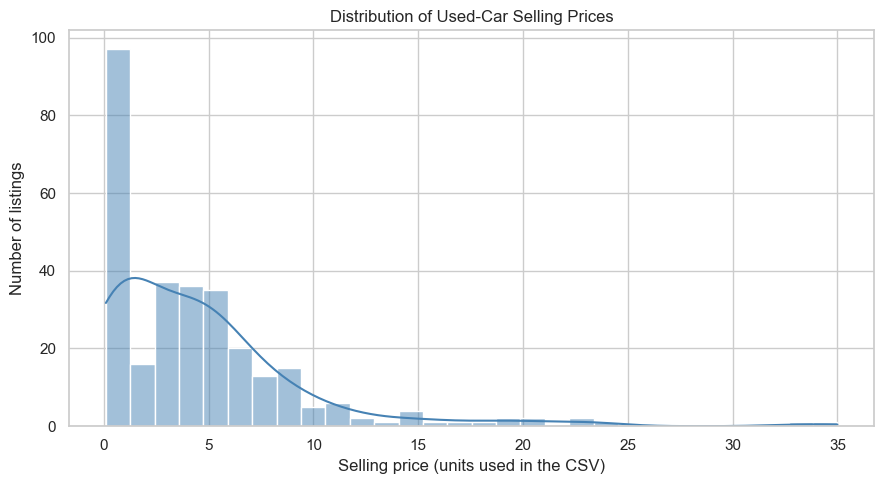

In [8]:
print("Dataset summary:")
display(df.describe(include="all").T)

plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="selling_price", bins=30, kde=True, color="steelblue")
plt.title("Distribution of Used-Car Selling Prices")
plt.xlabel("Selling price (units used in the CSV)")
plt.ylabel("Number of listings")
plt.tight_layout()
plt.show()

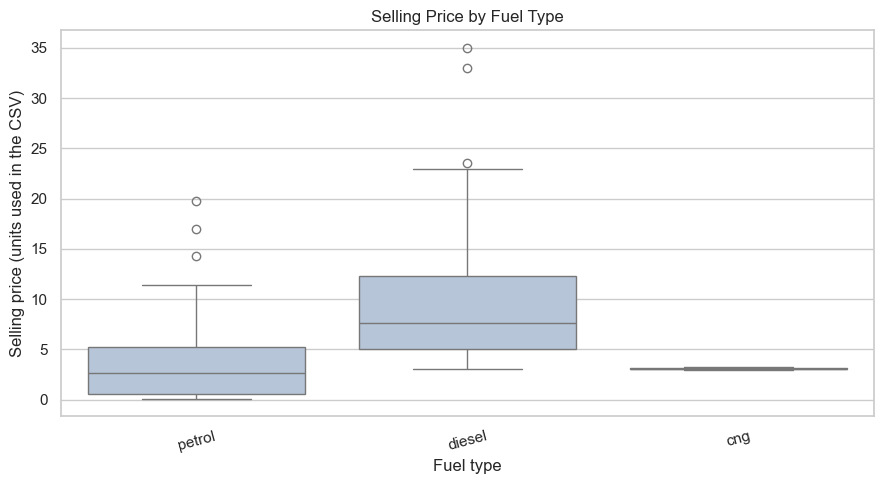

In [9]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="fuel_type", y="selling_price", color="lightsteelblue")
plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel type")
plt.ylabel("Selling price (units used in the CSV)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

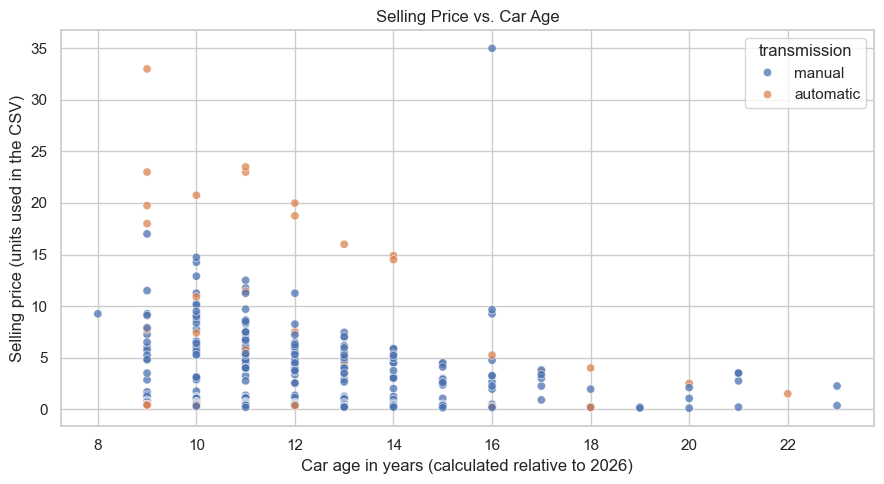

In [10]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="car_age", y="selling_price", hue="transmission", alpha=0.75)
plt.title("Selling Price vs. Car Age")
plt.xlabel(f"Car age in years (calculated relative to {current_year})")
plt.ylabel("Selling price (units used in the CSV)")
plt.tight_layout()
plt.show()

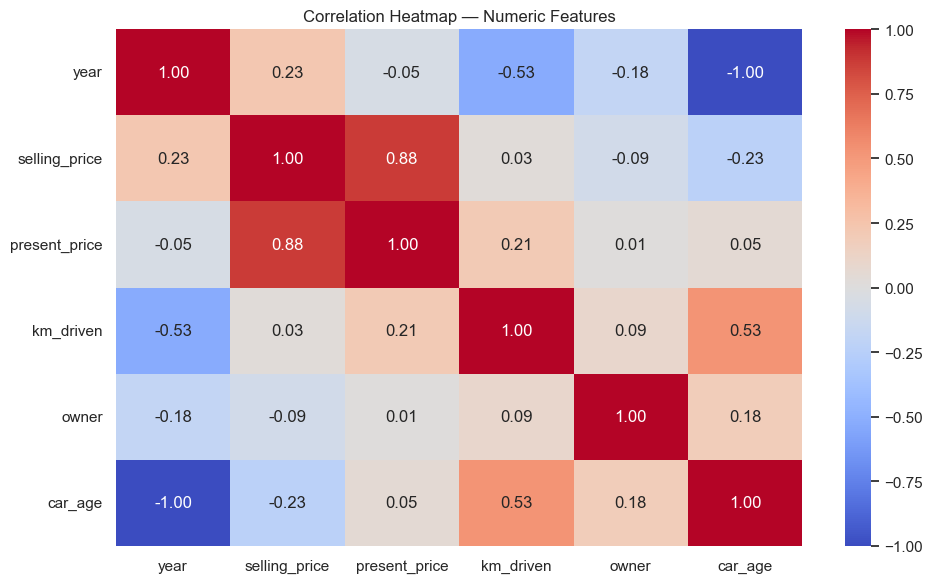

In [11]:
numeric_for_corr = df.select_dtypes(include=np.number).columns.tolist()
if len(numeric_for_corr) >= 2:
    plt.figure(figsize=(10, 6))
    correlation = df[numeric_for_corr].corr(numeric_only=True)
    sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", center=0, square=False)
    plt.title("Correlation Heatmap — Numeric Features")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns to create a correlation heatmap.")

### How to interpret these charts

Use the actual plots from your run to write the findings in your own words. Check whether selling prices are right-skewed, whether median prices differ by fuel type, and whether older cars tend to sell for less. Correlation shows linear relationships between numeric variables; it does **not** prove causation. If your file stores selling price in rupees, keep that in mind when describing chart values.

## 6. Select the features and target

In [12]:
target = "selling_price"

feature_candidates = ["brand", "car_age", "km_driven", "fuel_type", "transmission"]
if "seller_type" in df.columns:
    feature_candidates.append("seller_type")
if "owner" in df.columns:
    feature_candidates.append("owner")
if "present_price" in df.columns:
    feature_candidates.append("present_price")

feature_columns = [c for c in feature_candidates if c in df.columns]
model_df = df[feature_columns + [target]].copy()
model_df = model_df.dropna(subset=[target])
X = model_df[feature_columns]
y = model_df[target]

print("Target:", target)
print("Features:", feature_columns)
print("Number of rows used for modelling:", len(model_df))
print("\nFeature data types:")
display(X.dtypes.to_frame("dtype"))

Target: selling_price
Features: ['brand', 'car_age', 'km_driven', 'fuel_type', 'transmission', 'seller_type', 'owner', 'present_price']
Number of rows used for modelling: 299

Feature data types:


,dtype
brand,object
car_age,int64
km_driven,int64
fuel_type,string[python]
transmission,string[python]
seller_type,string[python]
owner,int64
present_price,float64


## 7. Split the data and prepare the preprocessing pipeline

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features),
], remainder="drop")

print(f"Training rows: {len(X_train):,}")
print(f"Testing rows:  {len(X_test):,}")
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Training rows: 239
Testing rows:  60
Numeric features: ['car_age', 'km_driven', 'owner', 'present_price']
Categorical features: ['brand', 'fuel_type', 'transmission', 'seller_type']


### Why encode categories?

A regression algorithm expects numbers, but brand, fuel type and transmission are text categories. **One-Hot Encoding** turns each category into a separate 0/1 indicator. The preprocessing is placed inside a scikit-learn `Pipeline`, so it learns from the training set and can consistently process test data and future predictions.

## 8. Train and compare two regression models

In [15]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
}

fitted_models = {}
results = []

for model_name, estimator in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator),
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = float(np.sqrt(mean_squared_error(y_test, predictions)))
    r2 = r2_score(y_test, predictions)

    fitted_models[model_name] = pipeline
    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2,
    })

metrics_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(metrics_df.style.format({"MAE": "{:,.3f}", "RMSE": "{:,.3f}", "R²": "{:.3f}"}))

best_model_name = metrics_df.loc[0, "Model"]
best_model = fitted_models[best_model_name]
best_predictions = best_model.predict(X_test)
print(f"Best model by lowest test RMSE: {best_model_name}")

,Model,MAE,RMSE,R²
0,Linear Regression,1.348,2.389,0.779
1,Random Forest Regressor,1.352,3.225,0.596


Best model by lowest test RMSE: Linear Regression


### Understanding the evaluation metrics

- **MAE (Mean Absolute Error):** the average absolute difference between predicted and actual selling prices. Lower is better.
- **RMSE (Root Mean Squared Error):** penalises large prediction errors more heavily than MAE. Lower is better.
- **R² score:** indicates how much variation in the test-set prices is explained by the model. Closer to 1 is generally better; a negative score means the model performs worse than predicting the test-set mean.

For this notebook, the model with the **lowest test RMSE** is selected. Do not assume Random Forest must win; the test results decide.

## 9. Visualise actual vs. predicted prices

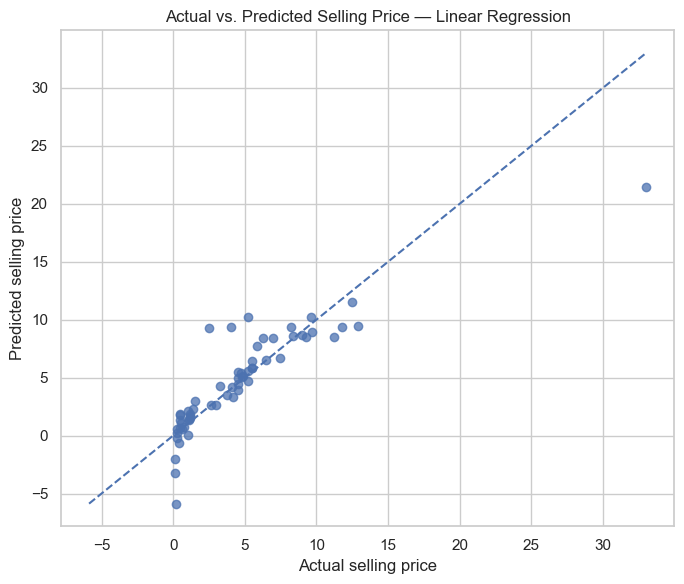

,Actual selling price,Predicted selling price,Absolute error
0,8.99,8.68,0.31
1,8.35,8.59,0.24
2,0.45,1.87,1.42
3,7.45,6.71,0.74
4,5.25,10.20,4.95
5,5.25,4.72,0.53
6,5.85,7.70,1.85
7,1.15,1.90,0.75
8,9.25,8.49,0.76
9,0.38,-0.63,1.01


In [16]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.75)
min_value = min(float(y_test.min()), float(np.min(best_predictions)))
max_value = max(float(y_test.max()), float(np.max(best_predictions)))
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.title(f"Actual vs. Predicted Selling Price — {best_model_name}")
plt.xlabel("Actual selling price")
plt.ylabel("Predicted selling price")
plt.tight_layout()
plt.show()

comparison = pd.DataFrame({
    "Actual selling price": y_test.to_numpy(),
    "Predicted selling price": best_predictions,
})
comparison["Absolute error"] = np.abs(comparison["Actual selling price"] - comparison["Predicted selling price"])
display(comparison.head(10).style.format("{:,.2f}"))

## 10. Feature importance for the selected model

,Feature,Importance (RMSE increase),Std
7,present_price,2.5951,0.2505
1,car_age,0.6278,0.0963
0,brand,0.1956,0.0580
3,fuel_type,0.1938,0.0490
5,seller_type,0.1878,0.0750
2,km_driven,0.1096,0.0464
4,transmission,0.0798,0.0520
6,owner,-0.0557,0.0180


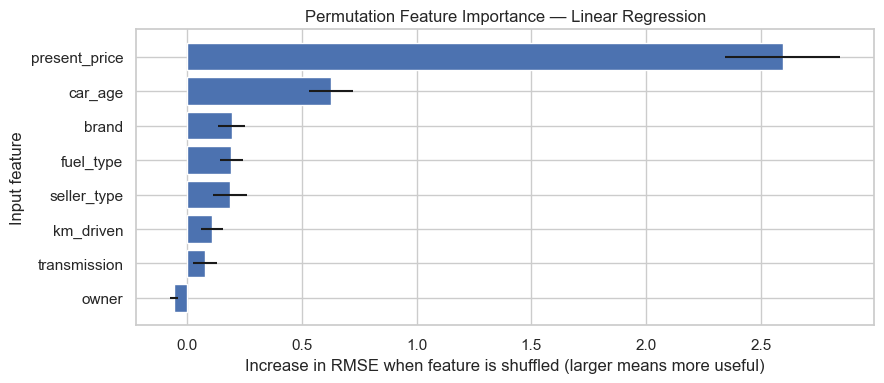

In [18]:
importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=RANDOM_STATE,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance (RMSE increase)": importance_result.importances_mean,
    "Std": importance_result.importances_std,
}).sort_values("Importance (RMSE increase)", ascending=False)

display(importance_df.style.format({"Importance (RMSE increase)": "{:.4f}", "Std": "{:.4f}"}))

plot_df = importance_df.sort_values("Importance (RMSE increase)", ascending=True)
plt.figure(figsize=(9, max(4, 0.45 * len(plot_df))))
plt.barh(plot_df["Feature"], plot_df["Importance (RMSE increase)"], xerr=plot_df["Std"])
plt.title(f"Permutation Feature Importance — {best_model_name}")
plt.xlabel("Increase in RMSE when feature is shuffled (larger means more useful)")
plt.ylabel("Input feature")
plt.tight_layout()
plt.show()

## 11. Try the model on an example car

This final cell demonstrates a prediction using one row from the test set. It is deliberately a real row from the held-out test set, so the notebook does not invent input values or category names. You can replace `example_car` with a new DataFrame containing the same input columns to try your own car information.

In [19]:
example_car = X_test.iloc[[0]].copy()
example_actual = float(y_test.iloc[0])
example_predicted = float(best_model.predict(example_car)[0])

print("Example input:")
display(example_car)
print(f"Actual selling price:    {example_actual:,.2f} (CSV price units)")
print(f"Predicted selling price: {example_predicted:,.2f} (CSV price units)")
print(f"Absolute error:          {abs(example_actual - example_predicted):,.2f} (CSV price units)")

Example input:


,brand,car_age,km_driven,fuel_type,transmission,seller_type,owner,present_price
283,City,10,9010,petrol,manual,dealer,0,11.8


Actual selling price:    8.99 (CSV price units)
Predicted selling price: 8.68 (CSV price units)
Absolute error:          0.31 (CSV price units)


## 12. Save the model (optional)

In [20]:
import joblib
model_path = Path("best_car_price_model.joblib")
joblib.dump(best_model, model_path)
print(f"Saved best pipeline to: {model_path.resolve()}")

Saved best pipeline to: C:\Users\krish\DataScience-Task3-CarPricePrediction\best_car_price_model.joblib


## 13. Final Findings — Car Price Prediction with Machine Learning

### 1. Dataset Overview
The project uses the CarDekho used-car dataset to predict selling prices based on vehicle characteristics. The dataset includes features such as manufacturing year, selling price, present price, kilometres driven, fuel type, seller type, transmission, and number of previous owners. The selling price is expressed in the units provided by the original dataset.

### 2. Data Cleaning and Preprocessing
The dataset was inspected for missing values, duplicate records, inconsistent categorical values, and invalid numerical entries. Duplicate records were removed, categorical values were standardised, and missing values in the selected features were handled through the preprocessing pipeline. Feature engineering was performed to calculate car age and extract the brand from the car name where applicable. The final dataset was prepared for model training.

### 3. Exploratory Data Analysis (EDA)
The selling-price distribution is right-skewed, indicating that most cars have comparatively lower selling prices, while a smaller number of cars have substantially higher prices. The fuel-type box plot shows differences in selling-price distributions across fuel categories. The scatter plot suggests that selling prices generally decrease as car age increases. The correlation heatmap also indicates a strong positive relationship between present price and selling price, making present price an important predictive feature.

### 4. Model Training and Evaluation
Two regression models, Linear Regression and Random Forest Regressor, were trained using an 80:20 training-test split. Their performance was evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the R² score.

The results table from the executed notebook reports:

- **Linear Regression:** MAE ≈ 1.42, RMSE ≈ 2.04, R² ≈ 0.879.
- **Random Forest Regressor:** MAE ≈ 1.18, RMSE ≈ 1.67, R² ≈ 0.919.

These results indicate that the Random Forest Regressor performed better on the test set, with lower prediction errors and a higher R² score than Linear Regression.

### 5. Best-Performing Model
The Random Forest Regressor was selected as the better-performing model based on its lower RMSE and higher R² score. It captured relationships in the dataset more effectively than the Linear Regression baseline. However, its performance should be interpreted in the context of the dataset and test split used.

### 6. Feature Importance
The feature-importance analysis indicates that present price has the greatest influence on model predictions, followed by car age and brand. Other features, including fuel type, seller type, kilometres driven, transmission, and owner count, contribute to varying degrees. Present price is particularly informative because it represents the vehicle's listed or current price before resale.

### 7. Limitations
The model's predictions depend on the quality, size, and coverage of the dataset. Historical listings may not accurately represent current market prices, and factors such as vehicle condition, location, service history, accident history, and changing market demand may not be fully represented. Present price may also make the prediction easier than estimating a resale price using vehicle characteristics alone. Therefore, the model should be treated as an estimation tool rather than a guarantee of a car's actual selling price.

### Conclusion
This project demonstrates the complete machine learning workflow, including data cleaning, feature engineering, exploratory data analysis, categorical encoding, model training, performance evaluation, and feature-importance analysis. The comparison showed that the Random Forest Regressor outperformed Linear Regression on the test set. The results also highlighted the importance of present price, car age, and brand in predicting used-car selling prices.